# Análisis exploratorio de incidencia delictiva en México

Los datos incluidos cubren enero de 2015 a junio de 2024. Se conserva el subtipo del archivo original para distinguir homicidio doloso de culposo y robo de vehículo automotor de otros robos. Las frecuencias son registros de incidencia delictiva y no se interpretan automáticamente como víctimas. Los meses vacíos de julio a diciembre de 2024 no son ceros y se excluyen.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
datos_crudos = pd.read_csv('data/datos_delitos.csv', encoding='ISO-8859-1')
datos_crudos = datos_crudos.rename(columns={'Año':'anio', 'Clave_Ent':'clave_ent', 'Entidad':'entidad',
    'Tipo de delito':'tipo_de_delito', 'Subtipo de delito':'subtipo_de_delito', 'Modalidad':'modalidad'})
meses = {'Enero':1,'Febrero':2,'Marzo':3,'Abril':4,'Mayo':5,'Junio':6,
         'Julio':7,'Agosto':8,'Septiembre':9,'Octubre':10,'Noviembre':11,'Diciembre':12}
df_detalle = datos_crudos.melt(
    id_vars=['anio','clave_ent','entidad','tipo_de_delito','subtipo_de_delito','modalidad'],
    value_vars=list(meses),var_name='nombre_mes',value_name='frecuencia'
).dropna(subset=['frecuencia']).copy()
df_detalle['frecuencia'] = df_detalle['frecuencia'].astype('int64')
df_detalle['mes'] = df_detalle['nombre_mes'].map(meses)
df_detalle['nombre_mes'] = df_detalle['nombre_mes'].str.lower()
df_detalle['fecha'] = pd.to_datetime({'year':df_detalle['anio'],'month':df_detalle['mes'],'day':1})
df = df_detalle.groupby(['anio','clave_ent','entidad','tipo_de_delito','nombre_mes','fecha'],
                       as_index=False)['frecuencia'].sum()
cobertura = df_detalle.groupby('anio')['mes'].nunique().rename('meses_observados')
print('Periodo observado:',df.fecha.min().date(),'a',df.fecha.max().date())
print('Tabla detallada:',df_detalle.shape,'| Tabla agregada:',df.shape)
display(cobertura.to_frame())

Periodo observado: 2015-01-01 a 2024-06-01
Tabla detallada: (357504, 10) | Tabla agregada: (145920, 7)


,meses_observados
anio,
2015,12
2016,12
2017,12
2018,12
2019,12
2020,12
2021,12
2022,12
2023,12


#### Ejercicio 1: Elige 3 estados de la república y grafica una serie de tiempo de la frecuencia abosluta de homicidios dolosos de enero 2015 a julio 2019 en estas tres entidades

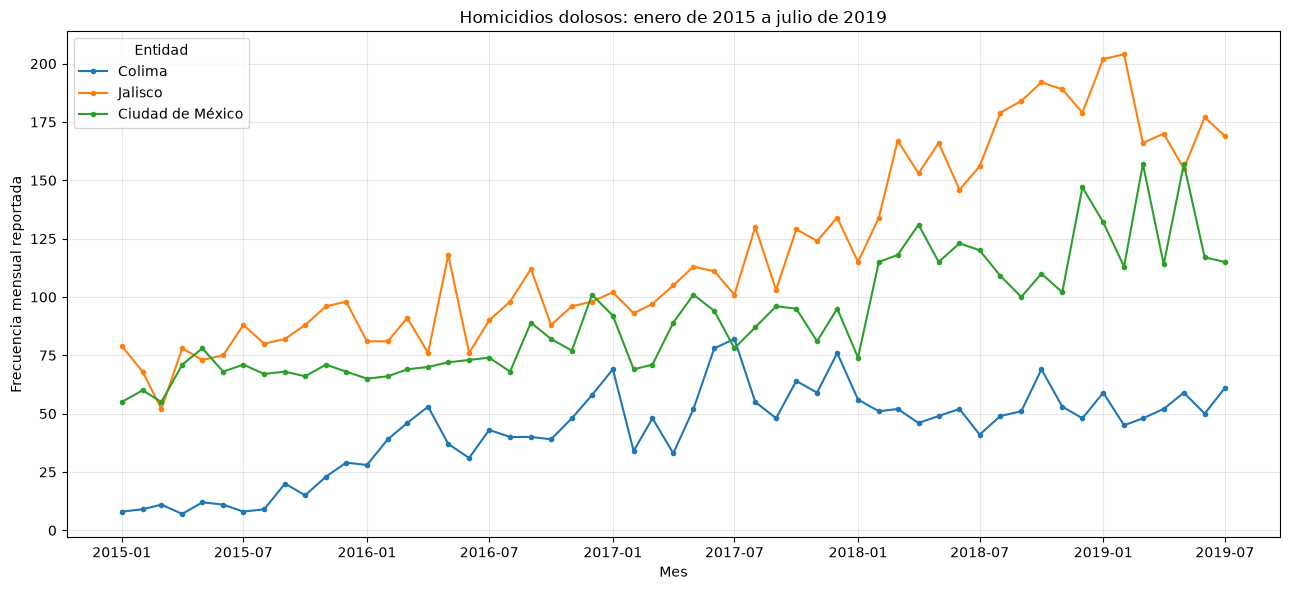

In [3]:
# Se agregan las modalidades de homicidio doloso, sin incluir el culposo.
estados_elegidos = ['Colima','Jalisco','Ciudad de México']
df_homicidios = df_detalle.loc[
    df_detalle.subtipo_de_delito.eq('Homicidio doloso')
    & df_detalle.entidad.isin(estados_elegidos)
    & df_detalle.fecha.between('2015-01-01','2019-07-01')
].groupby(['entidad','fecha'],as_index=False)['frecuencia'].sum()
fig,ax = plt.subplots(figsize=(13,6))
for estado in estados_elegidos:
    serie = df_homicidios.loc[df_homicidios.entidad.eq(estado)].sort_values('fecha')
    ax.plot(serie.fecha,serie.frecuencia,label=estado,marker='o',markersize=3)
ax.set(title='Homicidios dolosos: enero de 2015 a julio de 2019',
       xlabel='Mes',ylabel='Frecuencia mensual reportada')
ax.legend(title='Entidad')
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

#### Ejercicio 2: Contetas las siguientes  preguntas:
1. ¿Cuántos homicidios dolosos hubo en Colima en el 2018?
2. ¿Cuantos robos de vehículo automotor ha habido en el 2019?
3. Obten la suma de homicidos dolosos y feminidios en toda la República Mexicana en cada año.
4. ¿En qué mes y en qué municipio ha ocurrido el mayor número de feminicidios?
5. ¿En qué año y en qué estado ha ocurrido el mayor número de feminicidios?

In [4]:
print('RESPUESTAS DEL EJERCICIO 2\n')
homicidios_colima_2018 = df_detalle.loc[
    df_detalle.entidad.eq('Colima') & df_detalle.anio.eq(2018)
    & df_detalle.subtipo_de_delito.eq('Homicidio doloso'),'frecuencia'].sum()
print(f'1. Homicidios dolosos en Colima en 2018: {homicidios_colima_2018:,}')
robos_vehiculo_2019 = df_detalle.loc[df_detalle.anio.eq(2019)
    & df_detalle.subtipo_de_delito.eq('Robo de vehículo automotor'),'frecuencia'].sum()
print(f'2. Robos de vehículo automotor en México en 2019: {robos_vehiculo_2019:,}')
seleccion = df_detalle.loc[df_detalle.subtipo_de_delito.eq('Homicidio doloso')
                         | df_detalle.tipo_de_delito.eq('Feminicidio')]
suma_anual = seleccion.groupby(['anio','subtipo_de_delito']).frecuencia.sum().unstack(fill_value=0)
suma_anual = suma_anual.rename(columns={'Homicidio doloso':'homicidios_dolosos','Feminicidio':'feminicidios'})
suma_anual['suma'] = suma_anual.homicidios_dolosos+suma_anual.feminicidios
suma_anual = suma_anual.join(cobertura)
suma_anual['periodo'] = np.where(suma_anual.meses_observados.eq(12),'enero-diciembre','enero-junio (parcial)')
suma_anual = suma_anual.reset_index()
print('\n3. Homicidios dolosos y feminicidios por año:')
display(suma_anual)
print('\n4. No se puede determinar el municipio: los archivos solo contienen entidades federativas.')
df_feminicidios = df.loc[df.tipo_de_delito.eq('Feminicidio')].copy()
maximo_mensual = df_feminicidios.frecuencia.max()
maximos_mensuales = df_feminicidios.loc[df_feminicidios.frecuencia.eq(maximo_mensual),
    ['anio','entidad','nombre_mes','fecha','frecuencia']].sort_values(['fecha','entidad'])
print(f'Como referencia estatal, máximo entidad-mes = {maximo_mensual}; todos los empates:')
display(maximos_mensuales)
fem_anual_estado = df_feminicidios.groupby(['anio','entidad'],as_index=False).frecuencia.sum()
fem_anual_estado = fem_anual_estado.merge(cobertura.reset_index(),on='anio',validate='many_to_one')
maximo_anual = fem_anual_estado.frecuencia.max()
maximos_anuales = fem_anual_estado.loc[fem_anual_estado.frecuencia.eq(maximo_anual)].sort_values(['anio','entidad'])
print('\n5. Máximo acumulado por año y entidad entre los periodos observados:')
display(maximos_anuales)
print('2015-2023 cubren doce meses; 2024 solo enero-junio, no un año completo.')

RESPUESTAS DEL EJERCICIO 2

1. Homicidios dolosos en Colima en 2018: 617
2. Robos de vehículo automotor en México en 2019: 187,661

3. Homicidios dolosos y feminicidios por año:


,anio,feminicidios,homicidios_dolosos,suma,meses_observados,periodo
0,2015,413,16119,16532,12,enero-diciembre
1,2016,608,20148,20756,12,enero-diciembre
2,2017,744,25033,25777,12,enero-diciembre
3,2018,899,29096,29995,12,enero-diciembre
4,2019,944,29501,30445,12,enero-diciembre
5,2020,947,28839,29786,12,enero-diciembre
6,2021,981,28282,29263,12,enero-diciembre
7,2022,961,26279,27240,12,enero-diciembre
8,2023,832,25287,26119,12,enero-diciembre
9,2024,401,12854,13255,6,enero-junio (parcial)



4. No se puede determinar el municipio: los archivos solo contienen entidades federativas.
Como referencia estatal, máximo entidad-mes = 19; todos los empates:


,anio,entidad,nombre_mes,fecha,frecuencia
83717,2020,México,julio,2020-07-01,19
99073,2021,México,agosto,2021-08-01,19
114442,2022,México,octubre,2022-10-01,19



5. Máximo acumulado por año y entidad entre los periodos observados:


,anio,entidad,frecuencia,meses_observados
176,2020,México,151,12


2015-2023 cubren doce meses; 2024 solo enero-junio, no un año completo.


**Respuestas e interpretación del ejercicio 2**

1. **617 homicidios dolosos** en Colima durante 2018, sumando modalidades y excluyendo homicidios culposos.
2. **187,661 robos de vehículo automotor** en el país durante 2019. No se incluyen otros subtipos de robo.
3. Las sumas anuales de homicidios dolosos y feminicidios son: 2015 **16,532**; 2016 **20,756**; 2017 **25,777**; 2018 **29,995**; 2019 **30,445**; 2020 **29,786**; 2021 **29,263**; 2022 **27,240**; 2023 **26,119**; y 2024 **13,255**, esta última **solo de enero a junio**. La tabla separa ambos delitos y muestra la cobertura.
4. **No puede identificarse un municipio** con estos archivos estatales. Como referencia, el máximo de una **entidad en un mes** es **19 feminicidios** en el Estado de México (México en la base), con tres empates: **julio de 2020, agosto de 2021 y octubre de 2022**. Este resultado estatal no responde al nivel municipal ni es el máximo mensual del total nacional.
5. El mayor acumulado de una entidad en un año observado es el del **Estado de México en 2020, con 151 feminicidios**. Ese año tiene doce meses; 2024 solo tiene seis y no debe compararse como año completo.

#### Ejercicio 3: Haz una gráfica de pastel de tipos de delito. Deberás crear una gráfica para cada año. Utilzia la función subplots de matplotlib

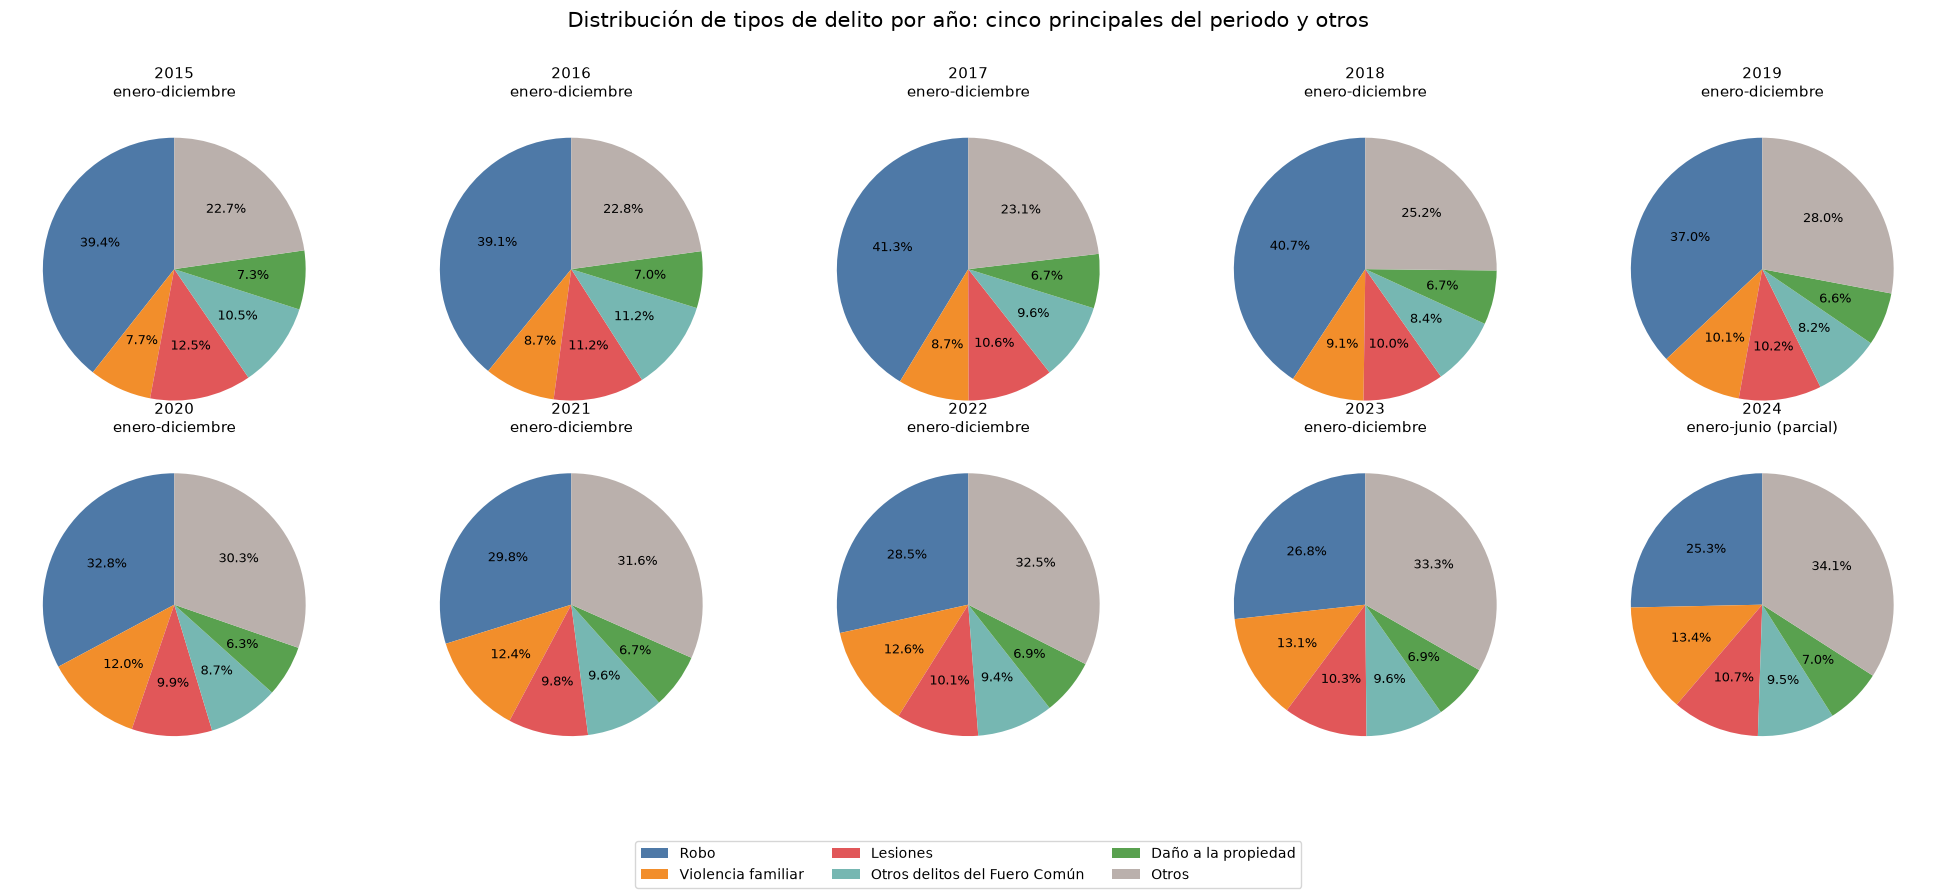

In [5]:
# Cinco categorías fijas: cada color mantiene su significado en todos los años.
tipos_top = df.groupby('tipo_de_delito').frecuencia.sum().nlargest(5).index.tolist()
categorias = tipos_top+['Otros']
colores = ['#4e79a7','#f28e2b','#e15759','#76b7b2','#59a14f','#bab0ac']
years = sorted(df.anio.unique())
ncols = 5
nrows = int(np.ceil(len(years)/ncols))
fig,axes = plt.subplots(nrows,ncols,figsize=(20,9),squeeze=False)
for ax,yr in zip(axes.flat,years):
    resumen = df.loc[df.anio.eq(yr)].groupby('tipo_de_delito').frecuencia.sum()
    valores = [resumen.get(tipo,0) for tipo in tipos_top]
    valores.append(resumen.loc[~resumen.index.isin(tipos_top)].sum())
    wedges,_,_ = ax.pie(valores,colors=colores,startangle=90,
        autopct=lambda pct:f'{pct:.1f}%' if pct>=2 else '',textprops={'fontsize':9})
    periodo = 'enero-diciembre' if cobertura.loc[yr]==12 else 'enero-junio (parcial)'
    ax.set_title(f'{yr}\n{periodo}',fontsize=11)
for ax in list(axes.flat)[len(years):]: ax.set_visible(False)
fig.legend(wedges,categorias,loc='lower center',ncol=3,fontsize=10)
fig.suptitle('Distribución de tipos de delito por año: cinco principales del periodo y otros',fontsize=15)
fig.tight_layout(rect=(0,0.12,1,0.95))
plt.show()

---
#### Calcula la tasa por 100,000 habitantes

Para un periodo: $tasa=(delitos\ del\ periodo/población)\times100,000$.

Si el numerador es mensual, multiplicar la tasa por 12 es una **anualización del mes**, una extrapolación; no es el total observado del año. Si ya se sumaron doce meses, la tasa del acumulado es anual y **no se vuelve a multiplicar por 12**.

Se usa como denominador fijo la población de 2015. Cinco valores del CSV estaban intercambiados; se corrigen en memoria con la [tabla por entidad de INEGI, Encuesta Intercensal 2015, página 14](https://www.inegi.org.mx/contenidos/programas/intercensal/2015/doc/eic_2015_presentacion.pdf#page=14). El CSV original se conserva.

Son tasas calculadas para este ejercicio con referencia demográfica fija, no tasas oficiales ajustadas por la población de cada año. La fuente demográfica corresponde a población en viviendas particulares habitadas.

In [6]:
pobs = pd.read_csv('data/poblacion_entidades_2015.csv',encoding='ISO-8859-1',sep=';')
pobs = pobs[['Cve_Entidad','Entidad','Poblacion']].rename(columns={
    'Cve_Entidad':'clave_entidad','Entidad':'entidad','Poblacion':'poblacion'})
pobs['poblacion_archivo'] = pobs.poblacion
# Correcciones verificadas en la tabla primaria de INEGI citada arriba.
correcciones_poblacion = {5:2954915,6:711235,7:5217908,8:3556574,9:8918653}
for clave,poblacion_correcta in correcciones_poblacion.items():
    pobs.loc[pobs.clave_entidad.eq(clave),'poblacion'] = poblacion_correcta
pobs[['poblacion','poblacion_archivo']] = pobs[['poblacion','poblacion_archivo']].astype('int64')
print('Correcciones respecto del CSV de población original:')
display(pobs.loc[pobs.poblacion.ne(pobs.poblacion_archivo)])

Correcciones respecto del CSV de población original:


,clave_entidad,entidad,poblacion,poblacion_archivo
4,5,Coahuila de Zaragoza,2954915,5217908
5,6,Colima,711235,3556574
6,7,Chiapas,5217908,8918653
7,8,Chihuahua,3556574,2954915
8,9,Ciudad de México,8918653,711235


In [7]:
# Cada fila es un tipo de delito, una entidad y un mes observado.
df_tasas = df.merge(pobs[['clave_entidad','poblacion']],
    left_on='clave_ent',right_on='clave_entidad',how='left',validate='many_to_one').drop(columns='clave_entidad')
df_tasas['tasa'] = df_tasas.frecuencia/df_tasas.poblacion*100000
df_tasas['tasa_anualizada'] = df_tasas.tasa*12
print('Tasa mensual y anualización del mes por cada 100,000 habitantes (población fija de 2015):')
display(df_tasas.head())

Tasa mensual y anualización del mes por cada 100,000 habitantes (población fija de 2015):


,anio,clave_ent,entidad,tipo_de_delito,nombre_mes,fecha,frecuencia,poblacion,tasa,tasa_anualizada
0,2015,1,Aguascalientes,Aborto,abril,2015-04-01,0,1312544,0.000000,0.000000
1,2015,1,Aguascalientes,Aborto,agosto,2015-08-01,0,1312544,0.000000,0.000000
2,2015,1,Aguascalientes,Aborto,diciembre,2015-12-01,0,1312544,0.000000,0.000000
3,2015,1,Aguascalientes,Aborto,enero,2015-01-01,0,1312544,0.000000,0.000000
4,2015,1,Aguascalientes,Aborto,febrero,2015-02-01,3,1312544,0.228564,2.742765


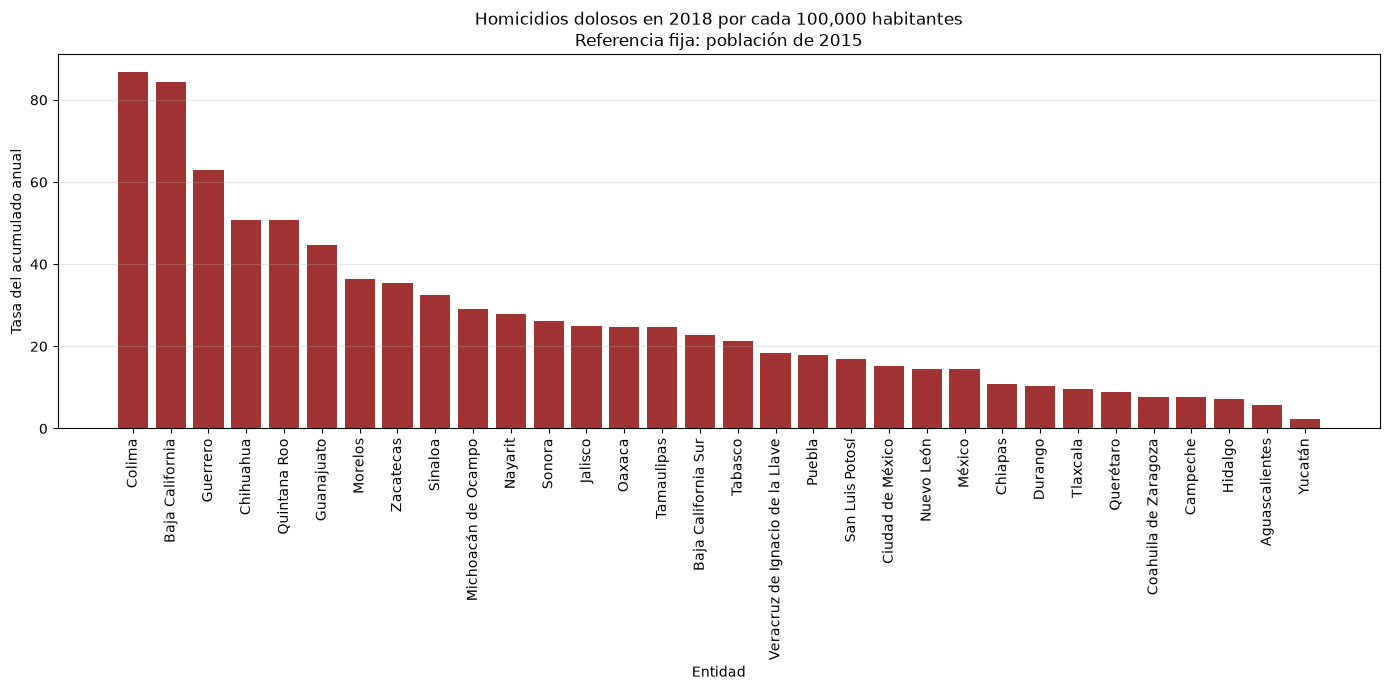

Cinco mayores tasas de homicidio doloso en 2018 con población de referencia 2015:


,anio,clave_ent,entidad,frecuencia,poblacion,meses_observados,tasa_periodo
101,2018,6,Colima,617,711235,12,86.750511
97,2018,2,Baja California,2798,3315766,12,84.384724
107,2018,12,Guerrero,2222,3533251,12,62.888258
103,2018,8,Chihuahua,1809,3556574,12,50.863556
118,2018,23,Quintana Roo,763,1501562,12,50.813753


In [8]:
# Homicidio DOLOSO: sumar el año y dividir por población una sola vez.
homicidios_anual = df_detalle.loc[df_detalle.subtipo_de_delito.eq('Homicidio doloso')].groupby(
    ['anio','clave_ent','entidad'],as_index=False).frecuencia.sum()
homicidios_anual = homicidios_anual.merge(pobs[['clave_entidad','poblacion']],
    left_on='clave_ent',right_on='clave_entidad',validate='many_to_one').drop(columns='clave_entidad')
homicidios_anual = homicidios_anual.merge(cobertura.reset_index(),on='anio',validate='many_to_one')
homicidios_anual['tasa_periodo'] = homicidios_anual.frecuencia/homicidios_anual.poblacion*100000
# 2018 tiene doce meses; la tasa del acumulado de 2024 solo sería semestral.
homicidios_2018 = homicidios_anual.loc[homicidios_anual.anio.eq(2018)].sort_values('tasa_periodo',ascending=False)
fig,ax = plt.subplots(figsize=(14,7))
ax.bar(homicidios_2018.entidad,homicidios_2018.tasa_periodo,color='darkred',alpha=0.8)
ax.set(title='Homicidios dolosos en 2018 por cada 100,000 habitantes\nReferencia fija: población de 2015',
       xlabel='Entidad',ylabel='Tasa del acumulado anual')
ax.tick_params(axis='x',rotation=90)
ax.grid(axis='y',alpha=0.3)
fig.tight_layout()
plt.show()
print('Cinco mayores tasas de homicidio doloso en 2018 con población de referencia 2015:')
display(homicidios_2018.head(5))